# Feature Importance, Done Honestly

Rigor pass 3. Tree impurity importance (`feature_importances_`) is biased toward high-cardinality continuous features. **Permutation importance**, measured on the held-out test set, asks the real question: how much does ROC AUC drop when a feature is shuffled? This notebook computes both and compares them, using the unweighted reference tree.

Logic in `src/importance.py`.

In [1]:
import sys, pathlib
_root = next(p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p/'src').exists())
sys.path.insert(0, str(_root))
import matplotlib.pyplot as plt
from src.importance import feature_importance

In [2]:
imp = feature_importance(scoring='roc_auc', n_repeats=30)
imp

,feature,perm_importance,perm_std,impurity_importance
0,Income,0.2772,0.0128,0.4693
1,Education,0.1289,0.0182,0.3407
2,Family,0.0697,0.0114,0.1441
3,CCAvg,0.0350,0.0052,0.0429
4,Experience,0.0000,0.0000,0.0000
5,Mortgage,0.0000,0.0000,0.0000
6,Securities_Account,0.0000,0.0000,0.0000
7,CD_Account,0.0000,0.0000,0.0000
8,Online,0.0000,0.0000,0.0000
9,CreditCard,0.0000,0.0000,0.0000


## Reading it

Both methods rank the same top four: **Income** dominates, then **Education**, **Family**, **CCAvg**. The other seven features have zero permutation importance: shuffling them does not change test AUC, so a four-feature model would perform identically. Note the scale difference: impurity gives Income ~0.47 of a unit-sum total, while permutation shows a ~0.28 AUC drop. Impurity overstates concentration; trust permutation for magnitude.

A zero is **redundancy, not irrelevance**: CD_Account, a strong standalone predictor on this data, shows zero here only because Income/Education/Family/CCAvg already separate the classes.

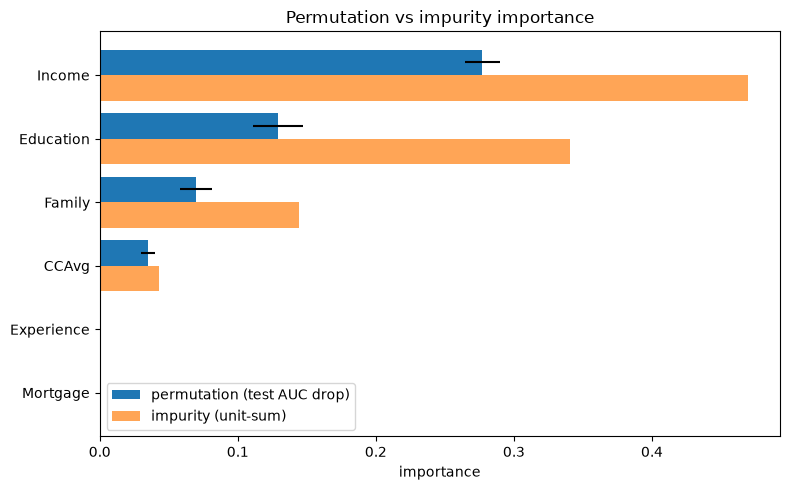

In [3]:
top = imp.head(6).iloc[::-1]
import numpy as np
y = np.arange(len(top)); h=0.4
plt.figure(figsize=(8,5))
plt.barh(y+h/2, top['perm_importance'], height=h, xerr=top['perm_std'], label='permutation (test AUC drop)')
plt.barh(y-h/2, top['impurity_importance'], height=h, label='impurity (unit-sum)', alpha=.7)
plt.yticks(y, top['feature']); plt.xlabel('importance'); plt.legend()
plt.title('Permutation vs impurity importance'); plt.tight_layout()
plt.savefig(_root/'results'/'feature_importance.png', dpi=120); plt.show()

## Substantive finding

Loan acceptance is driven by **income** (by far), then **education level**, **family size**, and **credit-card spending**. Demographics like age and tenure add nothing. The signal is concentrated enough that four features reproduce the full model. See `docs/learnings.md`.